# 06 - Knowledge distillation

- La nuova loss  per lo student è alpha·CE(y, student) + (1−alpha)·T²·KL(softmax(teacher/T) ‖ softmax(student/T)).
- del resto rimane invariato per un confronto equo (anche il training invariato)

In [1]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import json
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from src.data import get_dataloaders
from src.models import build_model
from src.train import get_device, init_weights, evaluate
from src.metrics import profile_model, save_result
from src.distill import distillation_loss, fit_kd

device = get_device()
torch.backends.cudnn.benchmark = True
train_loader, val_loader, test_loader = get_dataloaders("../data", batch_size=128)

teacher = build_model("teacher")
teacher.load_state_dict(torch.load("../checkpoints/teacher_baseline.pt", map_location=device))
teacher.to(device).eval()
print("teacher val acc:", evaluate(teacher, val_loader, device)[1])   # atteso 0.8984

Device: cpu


c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


teacher val acc: 0.8984


Test della temperatura per verificare appiattimento

In [2]:
x, y = next(iter(val_loader))
with torch.no_grad():
    logits = teacher(x.to(device))[:3].cpu()
for T in [1, 4]:
    print(f"T={T}:\n", torch.softmax(logits / T, dim=1).round(decimals=3), "\n")

T=1:
 tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0010, 0.0000, 0.0000, 0.9990, 0.0000,
         0.0000]]) 

T=4:
 tensor([[0.0020, 0.0030, 0.0090, 0.0140, 0.0060, 0.0060, 0.9530, 0.0020, 0.0020,
         0.0040],
        [0.0490, 0.0380, 0.0130, 0.0130, 0.0080, 0.0100, 0.0140, 0.0080, 0.8130,
         0.0330],
        [0.0540, 0.0130, 0.0630, 0.0310, 0.0960, 0.0600, 0.0190, 0.6180, 0.0160,
         0.0290]]) 



Test della loss (se lo student coincide con il teacher il termine soft deve essere zero; con alpha=1 resta solo la CE):

In [3]:
t = torch.randn(8, 10)
y_t = torch.randint(0, 10, (8,))
print(distillation_loss(t, t, y_t, T=4, alpha=0.0).item())                      # ~0
print(distillation_loss(t, t, y_t, T=4, alpha=1.0).item(),
      nn.functional.cross_entropy(t, y_t).item())                                # uguali

-1.7881393432617188e-07
2.4593658447265625 2.4593658447265625


Training student


In [4]:
T, ALPHA = 4.0, 0.1
EPOCHS = json.load(open("../results/student_baseline.json"))["epochs"]   # stesse epoche della baseline

torch.manual_seed(0)              # stesso seed e stessa init della baseline
student = build_model("student")
init_weights(student)
student.to(device)

history, train_time = fit_kd(student, teacher, train_loader, val_loader, device, epochs=EPOCHS,
                             T=T, alpha=ALPHA, ckpt_path="../checkpoints/student_kd.pt")

ep   1/30 | KD loss 10.969 | train acc 34.43 (teacher 97.76) | val acc 40.64 (best 40.64) | lr 0.0500
ep   2/30 | KD loss 8.454 | train acc 48.83 (teacher 97.82) | val acc 50.54 (best 50.54) | lr 0.0499
ep   3/30 | KD loss 7.415 | train acc 55.13 (teacher 97.70) | val acc 55.92 (best 55.92) | lr 0.0495
ep   4/30 | KD loss 6.549 | train acc 59.44 (teacher 97.79) | val acc 61.54 (best 61.54) | lr 0.0488
ep   5/30 | KD loss 5.993 | train acc 61.95 (teacher 97.80) | val acc 64.52 (best 64.52) | lr 0.0478
ep   6/30 | KD loss 5.531 | train acc 64.38 (teacher 97.76) | val acc 65.90 (best 65.90) | lr 0.0467
ep   7/30 | KD loss 5.178 | train acc 66.38 (teacher 97.78) | val acc 62.26 (best 65.90) | lr 0.0452
ep   8/30 | KD loss 4.847 | train acc 68.04 (teacher 97.82) | val acc 65.42 (best 65.90) | lr 0.0436
ep   9/30 | KD loss 4.586 | train acc 69.34 (teacher 97.76) | val acc 65.36 (best 65.90) | lr 0.0417
ep  10/30 | KD loss 4.353 | train acc 70.36 (teacher 97.87) | val acc 64.28 (best 65.90) |

Valutazione, confronto con la baseline e salvataggio

In [6]:
_, val_acc = evaluate(student, val_loader, device)
_, test_acc = evaluate(student, test_loader, device)
prof = profile_model(student.cpu(), dtype="fp32")
save_result("student_kd", val_acc=val_acc, test_acc=test_acc, T=T, alpha=ALPHA,
            epochs=EPOCHS, train_time_s=train_time, **prof)

base = json.load(open("../results/student_baseline.json"))
tch = json.load(open("../results/teacher_baseline.json"))
closed = (test_acc - base["test_acc"]) / (tch["test_acc"] - base["test_acc"])
print(f"teacher      : test {tch['test_acc'] * 100:.2f}")
print(f"student base : test {base['test_acc'] * 100:.2f}")
print(f"student KD   : test {test_acc * 100:.2f}  (T={T}, alpha={ALPHA})")

teacher      : test 89.28
student base : test 80.55
student KD   : test 80.04  (T=4.0, alpha=0.1)


Su singolo seed e test piccolo differenze di 1% non danno differenze significative, possibili motivazioni: 
- nonostante la temperatura il teacher ha delle distribuzioni molto "hard like"
- 10 classi sono poche quindi c’è meno struttura di somiglianze da trasferire che in dataset con molte classi, e i guadagni della distillation tendono a essere modesti

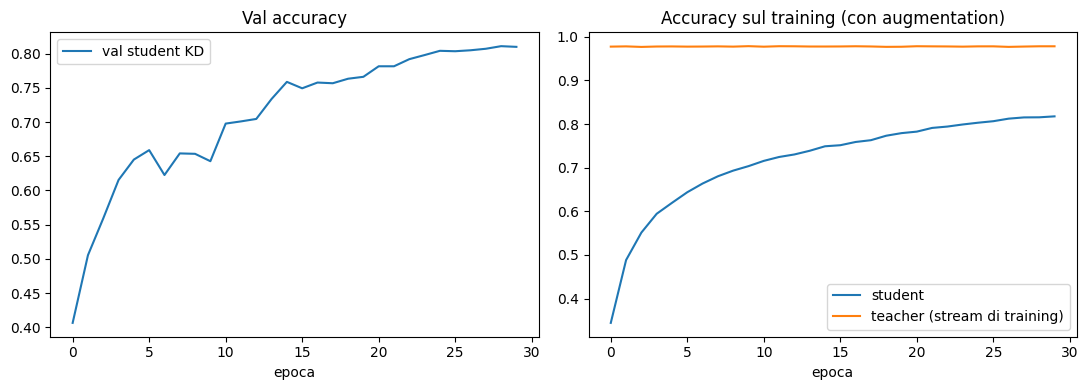

In [7]:
# curve di apprendimento 
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["val_acc"], label="val student KD")
ax[0].set_title("Val accuracy"); ax[0].set_xlabel("epoca"); ax[0].legend()
ax[1].plot(history["train_acc"], label="student")
ax[1].plot(history["teacher_train_acc"], label="teacher (stream di training)")
ax[1].set_title("Accuracy sul training (con augmentation)"); ax[1].set_xlabel("epoca"); ax[1].legend()
plt.tight_layout(); plt.show()